# `bspricer` — guided tour

A tour of the library in five steps, each one a claim checked by running code:

1. the closed-form price agrees with a binomial tree and Monte Carlo;
2. the Greeks are the derivatives of the price, in natural units;
3. the hedged P&L decomposes **exactly** into gamma, theta and carry, and gamma + theta + carry is the dollar-gamma-weighted variance gap;
4. the replication error shrinks like $1/\sqrt{N}$, and selling volatility above the realised one earns the variance gap;
5. on real SPY closes, an at-the-money call sold at the VIX and hedged daily earned that gap on average, with a crash month.

The notebook runs offline from `data/sample/` in well under a minute. The full study, with the numbers quoted in the README, is `scripts/run_results.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bspricer as bs

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "sample"

S0, K, T, r, sigma, q = 100.0, 100.0, 0.25, 0.03, 0.20, 0.0
print(f"bspricer {bs.__version__}")

bspricer 0.9.0


## 1. One price, three methods

Black-Scholes-Merton in closed form, a Cox-Ross-Rubinstein tree (error of order $1/n$) and risk-neutral Monte Carlo (error of order $1/\sqrt{n}$): the Monte Carlo gap is judged in standard errors, not in absolute terms.

In [2]:
closed_form = bs.bs_price(S0, K, T, r, sigma, "call", q)
tree = {n: bs.crr_price(S0, K, T, r, sigma, n, "call", q) for n in (100, 1_000, 5_000)}
mc = bs.mc_price(S0, K, T, r, sigma, n_paths=1_000_000, seed=1, antithetic=True)

print(f"closed form      {closed_form:.6f}")
for n, value in tree.items():
    print(f"CRR, n = {n:>5}   {value:.6f}   error {value - closed_form:+.2e}")
print(
    f"Monte Carlo      {mc.price:.6f}   ({(mc.price - closed_form) / mc.std_error:+.2f} standard errors)"
)

put = bs.bs_price(S0, K, T, r, sigma, "put", q)
print(
    f"put-call parity residual: {closed_form - put - (S0 * np.exp(-q * T) - K * np.exp(-r * T)):.1e}"
)

closed form      4.357619
CRR, n =   100   4.347672   error -9.95e-03
CRR, n =  1000   4.356623   error -9.96e-04
CRR, n =  5000   4.357420   error -1.99e-04
Monte Carlo      4.347024   (-2.23 standard errors)
put-call parity residual: 0.0e+00


## 2. Greeks in natural units

`bs_greeks` returns raw partial derivatives: theta is $\partial V/\partial t$ **per year**, vega is per unit of volatility. Conversions to desk units happen only at display time. The analytical values are checked here against central finite differences; the test suite does this on a 240-point grid with a documented tolerance.

In [3]:
g = bs.bs_greeks(S0, K, T, r, sigma, "call", q)
h = 1e-3 * S0 * sigma * np.sqrt(T)
fd_delta = (bs.bs_price(S0 + h, K, T, r, sigma) - bs.bs_price(S0 - h, K, T, r, sigma)) / (2 * h)
fd_gamma = (
    bs.bs_price(S0 + h, K, T, r, sigma) - 2 * closed_form + bs.bs_price(S0 - h, K, T, r, sigma)
) / h**2
fd_theta = -(bs.bs_price(S0, K, T + 1e-5, r, sigma) - bs.bs_price(S0, K, T - 1e-5, r, sigma)) / 2e-5

pd.DataFrame(
    {
        "analytical": [g["delta"], g["gamma"], g["theta"], g["vega"], g["rho"]],
        "desk units": [
            g["delta"],
            g["gamma"],
            g["theta"] / 252,
            g["vega"] / 100,
            g["rho"] / 10_000,
        ],
        "unit": ["shares", "1/USD", "USD per trading day", "USD per vol point", "USD per bp"],
    },
    index=list(bs.GREEK_NAMES),
).assign(finite_difference=[fd_delta, fd_gamma, fd_theta, np.nan, np.nan])

,analytical,desk units,unit,finite_difference
delta,0.549738,0.549738,shares,0.549738
gamma,0.039584,0.039584,1/USD,0.039584
theta,-9.435240,-0.037441,USD per trading day,-9.435240
vega,19.791884,0.197919,USD per vol point,NaN
rho,12.654051,0.001265,USD per bp,NaN


In [4]:
print(f"PDE residual  Θ + ½σ²S²Γ + (r − q)SΔ − rV = {bs.bs_pde_residual(S0, K, T, r, sigma):.1e}")

PDE residual  Θ + ½σ²S²Γ + (r − q)SΔ − rV = 1.2e-15


## 3. The gamma / theta trade-off, exactly

A short call is delta-hedged daily on simulated paths with the right volatility. `delta_hedge(..., decompose=True)` splits the P&L at expiry into

$$\text{P\&L} = \sum_k e^{r(T-t_{k+1})}\Big[\underbrace{-\tfrac12\Gamma_k\,\delta S_k^2}_{\text{gamma}}\;\underbrace{-\,\Theta_k\,\Delta t}_{\text{theta}}\;+\;\underbrace{(e^{r\Delta t}-1)(V_k-\Delta_k S_k)+D_k}_{\text{carry}}\;+\;\varepsilon_k\Big] - \text{costs}.$$

The short-option hedger collects theta and pays gamma. Gamma and theta alone do **not** cancel: the financing of the hedge (carry) is the third term, and only the three together give the leading-order identity

$$\text{gamma} + \text{theta} + \text{carry} \approx \sum_k \tfrac12\Gamma_k S_k^2\Big[\sigma_h^2\Delta t - \big(\tfrac{\delta S_k}{S_k}\big)^2\Big].$$

In [5]:
paths = bs.simulate_gbm(S0, 0.07, sigma, T, n_steps=63, n_paths=20_000, seed=7)
res = bs.delta_hedge(paths, K, T, r, sigma, "call", q, decompose=True, keep_deltas=True)
d = res.decomposition

attribution = pd.Series(
    {
        "gamma": d.gamma.mean(),
        "theta": d.theta.mean(),
        "carry": d.carry.mean(),
        "residual": d.residual.mean(),
        "total P&L": res.mean,
    }
)
print(attribution.round(4).to_string())
print(f"\nmax |sum of terms - P&L| = {np.max(np.abs(d.total() - res.pnl)):.1e}")
print(
    f"mean P&L {res.mean:+.4f} ± {res.std_error:.4f} (s.e.), sd {res.std:.3f}  →  unbiased, but not riskless"
)
proxy = bs.variance_pnl(paths, K, T, r, sigma)
print(
    f"max |gamma + theta + carry - variance proxy| = {np.max(np.abs(d.gamma + d.theta + d.carry - proxy)):.1e}"
)

gamma       -1.9815
theta        2.3743
carry       -0.3961
residual     0.0021
total P&L   -0.0012

max |sum of terms - P&L| = 1.6e-13
mean P&L -0.0012 ± 0.0031 (s.e.), sd 0.434  →  unbiased, but not riskless
max |gamma + theta + carry - variance proxy| = 4.3e-05


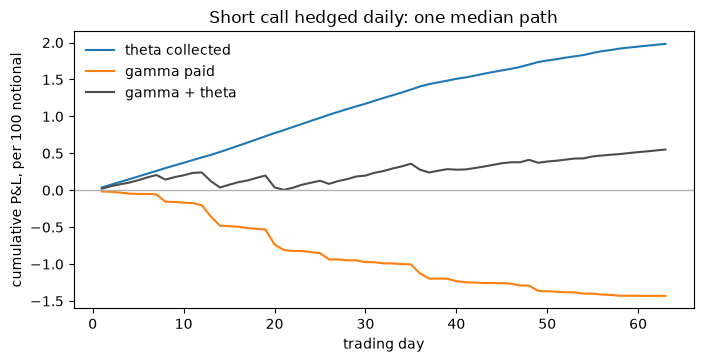

In [6]:
i = int(np.argmin(np.abs(res.pnl - np.median(res.pnl))))  # a path with the median P&L
path = paths[i]
greeks = [bs.bs_greeks(path[k], K, T - k * res.dt, r, sigma) for k in range(res.n_steps)]
gamma_steps = np.array(
    [-0.5 * g_k["gamma"] * (path[k + 1] - path[k]) ** 2 for k, g_k in enumerate(greeks)]
)
theta_steps = np.array([-g_k["theta"] * res.dt for g_k in greeks])

fig, ax = plt.subplots(figsize=(8, 3.6))
days = np.arange(1, res.n_steps + 1)
ax.plot(days, np.cumsum(theta_steps), label="theta collected")
ax.plot(days, np.cumsum(gamma_steps), label="gamma paid")
ax.plot(days, np.cumsum(theta_steps + gamma_steps), label="gamma + theta", color="0.3")
ax.axhline(0, color="0.7", linewidth=1)
ax.set(
    xlabel="trading day",
    ylabel="cumulative P&L, per 100 notional",
    title="Short call hedged daily: one median path",
)
ax.legend(frameon=False)
plt.show()

## 4. Discrete rebalancing and a wrong volatility

Same Brownian paths, observed at fewer dates (common random numbers): the standard deviation of the hedging error follows the Kamal-Derman approximation $\sqrt{\pi/4}\,\sigma\,\mathcal V/\sqrt N$. Selling at a volatility $\sigma_i$ above the realised $\sigma_r$ earns, on average, the dollar-gamma-weighted variance gap.

In [7]:
fine = bs.simulate_gbm(S0, 0.07, sigma, T, n_steps=504, n_paths=5_000, seed=3)
vega = g["vega"]
rows = []
for n in (8, 21, 63, 126, 252, 504):
    out = bs.delta_hedge(fine[:, :: 504 // n], K, T, r, sigma)
    rows.append({"N": n, "sd(P&L)": out.std, "Kamal-Derman": bs.kamal_derman_std(vega, sigma, n)})
table = pd.DataFrame(rows).set_index("N")
slope = np.polyfit(np.log(table.index), np.log(table["sd(P&L)"]), 1)[0]
print(f"log-log slope {slope:.3f} (theory -0.5)")
table.assign(ratio=table["sd(P&L)"] / table["Kamal-Derman"]).round(4)

log-log slope -0.488 (theory -0.5)


,sd(P&L),Kamal-Derman,ratio
N,,,
8,1.1507,1.2403,0.9278
21,0.7421,0.7655,0.9694
63,0.4324,0.4420,0.9783
126,0.3029,0.3125,0.9692
252,0.2158,0.2210,0.9765
504,0.1550,0.1563,0.9920


In [8]:
rows = []
for sigma_i in (0.16, 0.20, 0.24):
    out = bs.delta_hedge(paths, K, T, r, sigma_i)
    predicted = bs.variance_pnl(paths, K, T, r, sigma_i, sigma_realized=sigma).mean()
    rows.append(
        {"sold at": sigma_i, "mean P&L": out.mean, "s.e.": out.std_error, "predicted": predicted}
    )
pd.DataFrame(rows).round(4)

,sold at,mean P&L,s.e.,predicted
0,0.16,-0.7916,0.0039,-0.7913
1,0.20,-0.0012,0.0031,0.0000
2,0.24,0.7914,0.0036,0.7912


## 5. Real data: SPY 2020–2024, sold at the VIX

Every 21 trading days, sell a 21-day at-the-money call at the VIX close, with the 3-month T-bill rate, and delta-hedge it once a day on the observed SPY closes. The VIX is only a proxy for the implied volatility of that option (see the README limits).

In [9]:
market = bs.align_market_data(
    bs.load_price_series(DATA / "SPY_2020_2024.csv"),
    bs.load_fred_series(DATA / "VIXCLS_2020_2024.csv"),
    bs.load_fred_series(DATA / "DTB3_2020_2024.csv"),
)
trades = bs.short_vol_backtest(market, horizon=21)
summary = pd.Series(
    {
        "trades": len(trades),
        "mean P&L per 100 notional": trades["pnl"].mean(),
        "share of profitable months": (trades["pnl"] > 0).mean(),
        "share of months with VIX > realised": (
            trades["implied_vol"] > trades["realized_vol"]
        ).mean(),
        "worst month P&L": trades["pnl"].min(),
    }
)
print(summary.round(3).to_string())
worst = trades.nsmallest(3, "pnl").set_index("start")
worst[["implied_vol", "realized_vol", "pnl", "gamma", "theta"]].round(3)

trades                                 59.000
mean P&L per 100 notional               0.405
share of profitable months              0.797
share of months with VIX > realised     0.814
worst month P&L                        -2.044


,implied_vol,realized_vol,pnl,gamma,theta
start,,,,,
2020-03-04,0.320,0.898,-2.044,-2.970,0.378
2020-02-03,0.180,0.333,-0.869,-1.781,0.831
2024-07-08,0.124,0.194,-0.650,-1.383,0.884


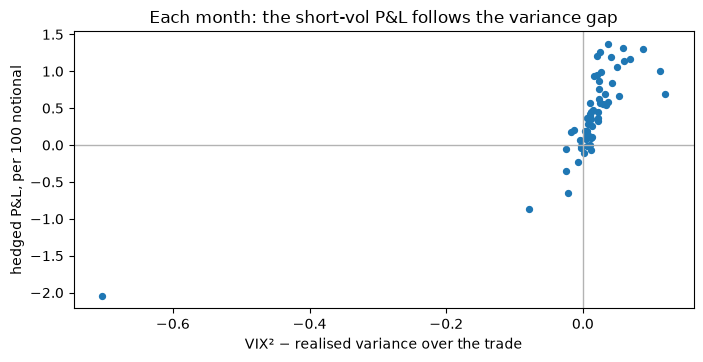

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(trades["implied_vol"] ** 2 - trades["realized_vol"] ** 2, trades["pnl"], s=18)
ax.axhline(0, color="0.7", linewidth=1)
ax.axvline(0, color="0.7", linewidth=1)
ax.set(
    xlabel="VIX² − realised variance over the trade",
    ylabel="hedged P&L, per 100 notional",
    title="Each month: the short-vol P&L follows the variance gap",
)
plt.show()

## 6. Implied volatility, and when it does not exist

`bs_implied_vol` inverts the price by Brent's method. When the time value is below the numerical resolution of the price (deep in the money, close to expiry) volatility is not identifiable, and the solver raises instead of returning an arbitrary number.

In [11]:
price = bs.bs_price(100.0, 110.0, 0.5, r, 0.27, "call")
print(f"round trip: {bs.bs_implied_vol(price, 100.0, 110.0, 0.5, r, 'call'):.12f}")

deep_itm = bs.bs_price(420.0, 310.0, 5 / 252, 0.05, 0.19, "call")
try:
    bs.bs_implied_vol(deep_itm, 420.0, 310.0, 5 / 252, 0.05, "call")
except bs.ImpliedVolError as err:
    print(f"ImpliedVolError: {err}")

round trip: 0.270000000000
ImpliedVolError: time value 0 is below the price resolution 4.2e-10: implied volatility is not identifiable
